<a href="https://colab.research.google.com/github/Perlangas28/Simulacion_2/blob/main/Modelo__SIR_con_pyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color="hotpink"> **Modelo SIR con pyMC**

**Alumna:** Perla Blancas Hernández

**Materia:** Investigación de Operaciones

**Maestro:** Ricardo Medel Esquivel

##<font color= "lightpink"> **Ajuste bayesiano de parámetros del modelo SIR con PyMC**

**Objetivo:** estimar los parámetros de transmisión y recuperación de una epidemia mediante inferencia bayesiana, utilizando Python y la biblioteca PyMC.

**Metodología:** se formulará el modelo SIR mediante ecuaciones diferenciales, se definirán distribuciones previas para los parámetros y se utilizará el muestreo MCMC para obtener sus distribuciones posteriores.

**Primero importamos las bibliotecas**, las cuales sirven para:


**pymc:** definir el modelo probabilístico y estimar los parámetros.



**pytensor:** representar y calcular las operaciones matemáticas del modelo.



**arviz:** analizar las muestras posteriores y revisar la convergencia.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import pytensor
import pytensor.tensor as pt
import arviz as az

##<font color= "lightpink"> **Formulación matemática del modelo SIR**

El modelo SIR representa una población cerrada dividida en tres:

- $S(t)$: personas susceptibles.
- $I(t)$: personas infectadas.
- $R(t)$: personas recuperadas.

La población total se conserva:

$
S(t)+I(t)+R(t)=N
$

La dinámica de la epidemia está descrita por:

$
\frac{dS}{dt}=-aSI
$

$
\frac{dI}{dt}=aSI-bI
$

$
\frac{dR}{dt}=bI
$

El parámetro $a$ representa la transmisión y $b$ la recuperación. El objetivo es estimarlos a partir de los infectados observados diariamente.

**Introducimos los datos**

,Día,Infectados observados
0,0,1
1,1,3
2,2,6
3,3,25
4,4,73
5,5,222
6,6,294
7,7,258
8,8,237
9,9,191


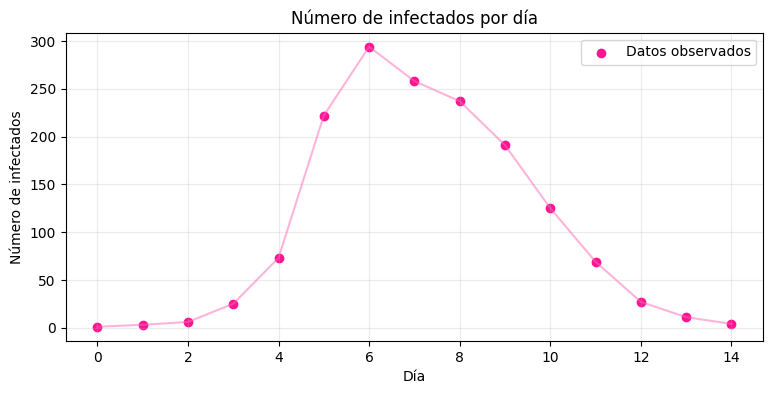

In [3]:
# Población total y condiciones iniciales
N = 763
S0 = 762
I0 = 1
R0 = 0

# Días de observación
dias = np.arange(15)

# Conteos diarios de infectados
I_datos = np.array([
    1, 3, 6, 25, 73,
    222, 294, 258, 237, 191,
    125, 69, 27, 11, 4
])

# Organizar la información en una tabla
datos = pd.DataFrame({
    "Día": dias,
    "Infectados observados": I_datos
})

display(datos)

# Graficar los datos observados
plt.figure(figsize=(9, 4))
plt.scatter(dias, I_datos, color="deeppink", label="Datos observados")
plt.plot(dias, I_datos, color="hotpink", alpha=0.5)
plt.title("Número de infectados por día")
plt.xlabel("Día")
plt.ylabel("Número de infectados")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

##<font color= "lightpink"> **Inferencia bayesiana**

La inferencia bayesiana combina la información previa sobre los parámetros con los datos observados para obtener una distribución posterior.

El teorema de Bayes se expresa como:


$p(a,b\mid \mathbf I) = \frac{p(\mathbf I\mid a,b)\,p(a,b)}
{p(\mathbf I)}$

Donde:

- $p(a,b)$ es la distribución previa o *prior*.
- $p(\mathbf I\mid a,b)$ es la verosimilitud de los datos.
- $p(a,b\mid\mathbf I)$ es la distribución posterior o *posterior*.
- $p(\mathbf I)$ es una constante de normalización.

Se utilizará una distribución Poisson para representar los conteos observados:

$
I_{\mathrm{obs},t}\sim
\operatorname{Poisson}(\lambda_t)
$

La media $\lambda_t$ se obtiene de la cantidad de infectados que predice el modelo SIR en el día $t$.

Como la distribución posterior no suele obtenerse directamente mediante una fórmula sencilla, se utilizará MCMC para generar muestras que permitan aproximarla.

**Construimos y ejecutamos el modelo en PyMC**

Esta es la celda central de todo el trabajo. Aquí se definen los parámetros desconocidos, se calcula la evolución del SIR y se comparan las predicciones con los datos reales.

In [4]:
# Paso de tiempo: una décima de día
dt = 0.1
pasos_por_dia = 10
n_pasos = 14 * pasos_por_dia

with pm.Model() as modelo_sir:

    # 1. Distribuciones previas de los parámetros
    a = pm.LogNormal(
        "a",
        mu=np.log(0.002),
        sigma=0.25
    )

    b = pm.LogNormal(
        "b",
        mu=np.log(0.43),
        sigma=0.25
    )

    # 2. Definir un paso del modelo SIR
    def paso_sir(indice, S_ant, I_ant, R_ant, a, b):

        contagios = a * S_ant * I_ant * dt
        recuperaciones = b * I_ant * dt

        S_nuevo = S_ant - contagios
        I_nuevo = I_ant + contagios - recuperaciones
        R_nuevo = R_ant + recuperaciones

        return S_nuevo, I_nuevo, R_nuevo

    # 3. Repetir las ecuaciones a lo largo del tiempo
    estados, actualizaciones = pytensor.scan(
        fn=paso_sir,
        sequences=[pt.arange(n_pasos)],
        outputs_info=[
            pt.as_tensor_variable(float(S0), dtype="float64"),
            pt.as_tensor_variable(float(I0), dtype="float64"),
            pt.as_tensor_variable(float(R0), dtype="float64")
        ],
        non_sequences=[a, b]
    )

    S_pasos, I_pasos, R_pasos = estados

    # 4. Incorporar las condiciones iniciales
    S_todos = pt.concatenate([
        pt.as_tensor_variable([float(S0)], dtype="float64"), S_pasos
    ])

    I_todos = pt.concatenate([
        pt.as_tensor_variable([float(I0)], dtype="float64"), I_pasos
    ])

    R_todos = pt.concatenate([
        pt.as_tensor_variable([float(R0)], dtype="float64"), R_pasos
    ])

    # 5. Extraer los resultados de cada día
    indices_diarios = np.arange(
        0, n_pasos + 1, pasos_por_dia
    )

    I_diario = I_todos[indices_diarios]

    # 6. Definir la media de los conteos observados
    media_infectados = pm.Deterministic(
        "media_infectados",
        pt.maximum(I_diario, 1e-6)
    )

    # 7. Verosimilitud Poisson
    observaciones = pm.Poisson(
        "observaciones",
        mu=media_infectados,
        observed=I_datos
    )

    # 8. Muestreo de la distribución posterior
    idata = pm.sample(
        draws=1500,
        tune=1500,
        chains=4,
        cores=2,
        target_accept=0.9,
        random_seed=123
    )

/tmp/ipykernel_1006/3566323943.py:34: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  estados, actualizaciones = pytensor.scan(


Output()

In [5]:
# Resumir las distribuciones posteriores de a y b
resumen = az.summary(
    idata,
    var_names=["a", "b"],
    hdi_prob=0.95,
    round_to=6
)

display(resumen)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,0.002274,0.000021,0.002234,0.002313,0.000000,0.000000,4964.113781,3912.499311,1.000351
b,0.482189,0.011068,0.459156,0.502226,0.000157,0.000132,4982.239982,3925.296116,1.000849


**Graficamos las distribuciones posteriores**

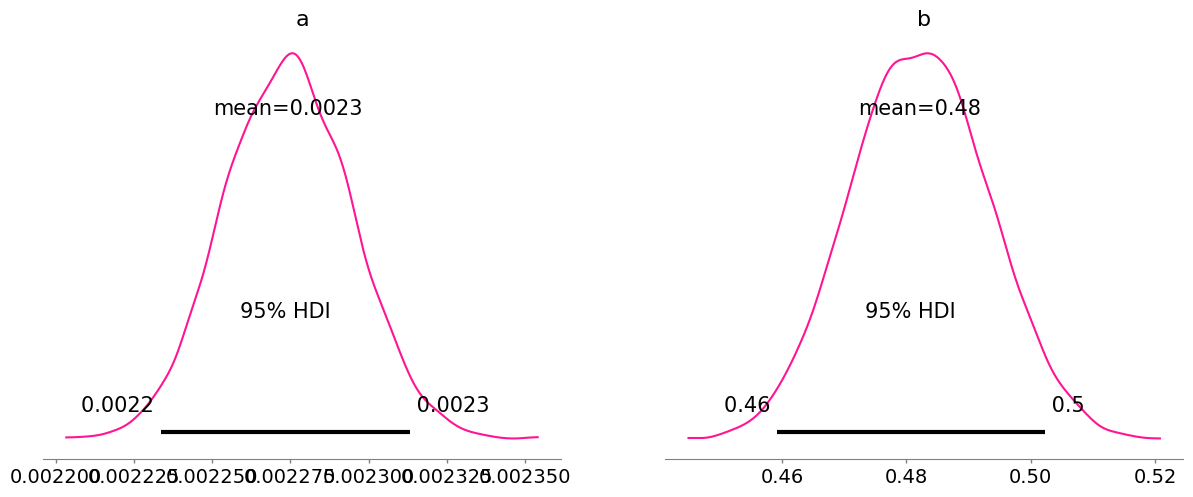

In [6]:
az.plot_posterior(
    idata,
    color="deeppink",
    var_names=["a", "b"],
    hdi_prob=0.95
)

plt.show()

**Revisamos las trazas MCMC**

Las trazas muestran cómo cambian las muestras de cada cadena a lo largo de las iteraciones.
- Buen comportamiento: las cadenas se mezclan y oscilan alrededor de una región estable.
- Posible problema: tendencias persistentes, cadenas separadas o largos periodos sin movimiento.

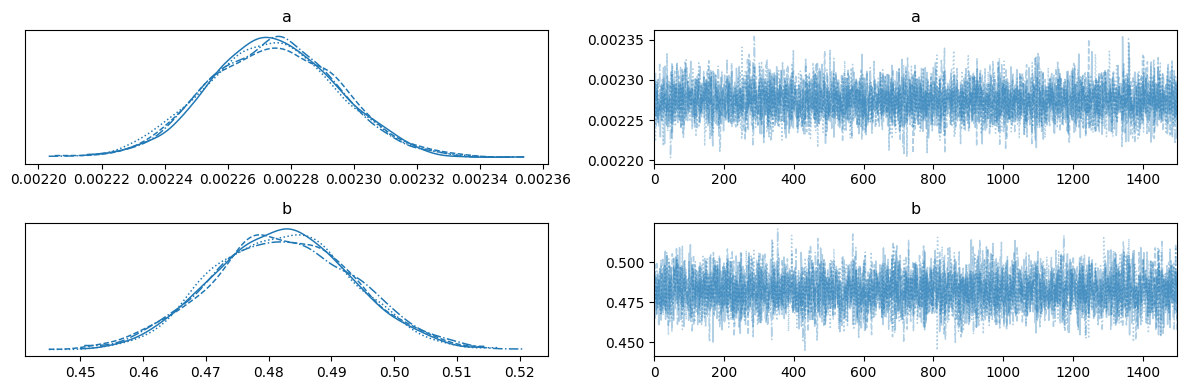

In [17]:
az.plot_trace(
    idata,
    var_names=["a", "b"]
)

plt.tight_layout()
plt.show()

**Comparamos el modelo con los datos observados**

Esta gráfica es fundamental porque permite evaluar si el modelo SIR reproduce razonablemente la evolución del brote.
* Los puntos rosas son los infectados observados.



* La línea morada representa la predicción del modelo con las medias posteriores estimadas de \(a\) y \(b\).



* Si la línea sigue de cerca los puntos, el modelo reproduce razonablemente la tendencia de los datos.



* Si hay diferencias importantes, puede haber ruido en los datos, limitaciones en el modelo o problemas con los supuestos utilizados.




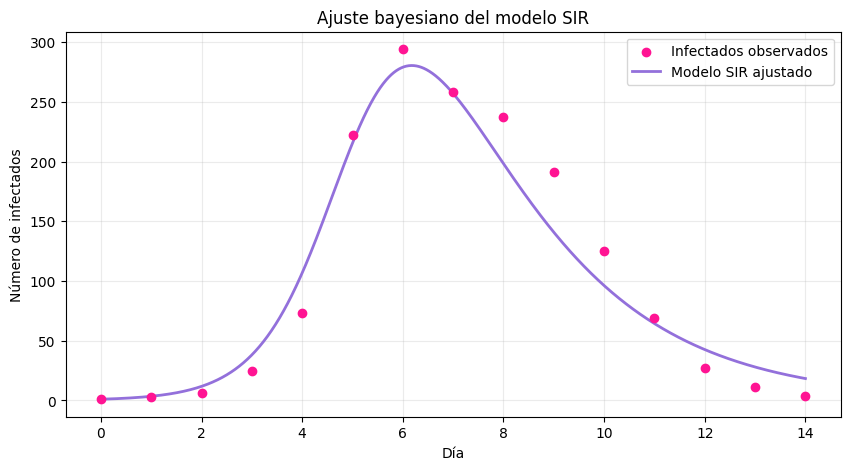

Estimación de a: 0.002274
Estimación de b: 0.482189


In [10]:
# Calcular las medias posteriores de los parámetros
a_estimado = float(idata.posterior["a"].mean().values)
b_estimado = float(idata.posterior["b"].mean().values)

# Simular el SIR con los parámetros estimados
def simular_sir(a, b, dt=0.01):
    S, I, R = float(S0), float(I0), float(R0)

    tiempos = [0.0]
    infectados = [I]

    for k in range(int(14 / dt)):
        contagios = a * S * I * dt
        recuperaciones = b * I * dt

        S -= contagios
        I += contagios - recuperaciones
        R += recuperaciones

        tiempos.append((k + 1) * dt)
        infectados.append(I)

    return np.array(tiempos), np.array(infectados)

tiempos, I_sim = simular_sir(a_estimado, b_estimado)

# Comparar observaciones y simulación
plt.figure(figsize=(10, 5))

plt.scatter(
    dias, I_datos,
    color="deeppink",
    label="Infectados observados",
    zorder=3
)

plt.plot(
    tiempos, I_sim,
    color="mediumpurple",
    linewidth=2,
    label="Modelo SIR ajustado"
)

plt.title("Ajuste bayesiano del modelo SIR")
plt.xlabel("Día")
plt.ylabel("Número de infectados")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print(f"Estimación de a: {a_estimado:.6f}")
print(f"Estimación de b: {b_estimado:.6f}")

**Graficamos los tres compartimentos**

Interpretación esperada:
- Los susceptibles disminuyen a medida que se contagian.
- Los infectados primero pueden aumentar y después disminuir.
- Los recuperados aumentan conforme las personas dejan de estar infectadas.
- La suma de los tres grupos debe permanecer aproximadamente igual a \(N\).
El error numérico debe ser pequeño, aunque puede variar ligeramente por la precisión de los cálculos.

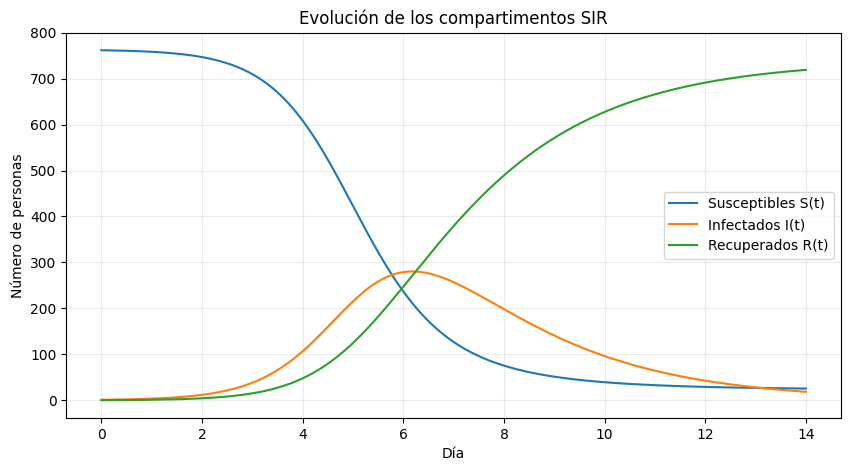

Error máximo de conservación: 0.0000000000


In [11]:
def simular_compartimentos(a, b, dt=0.01):
    S, I, R = float(S0), float(I0), float(R0)

    tiempos = [0.0]
    susceptibles = [S]
    infectados = [I]
    recuperados = [R]

    for k in range(int(14 / dt)):
        contagios = a * S * I * dt
        recuperaciones = b * I * dt

        S -= contagios
        I += contagios - recuperaciones
        R += recuperaciones

        tiempos.append((k + 1) * dt)
        susceptibles.append(S)
        infectados.append(I)
        recuperados.append(R)

    return tiempos, susceptibles, infectados, recuperados

t, S_sim, I_sim, R_sim = simular_compartimentos(
    a_estimado, b_estimado
)

plt.figure(figsize=(10, 5))
plt.plot(t, S_sim, label="Susceptibles S(t)")
plt.plot(t, I_sim, label="Infectados I(t)")
plt.plot(t, R_sim, label="Recuperados R(t)")

plt.title("Evolución de los compartimentos SIR")
plt.xlabel("Día")
plt.ylabel("Número de personas")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

# Verificar la conservación de la población
error = np.max(
    np.abs(np.array(S_sim) + np.array(I_sim) +
           np.array(R_sim) - N)
)

print(f"Error máximo de conservación: {error:.10f}")

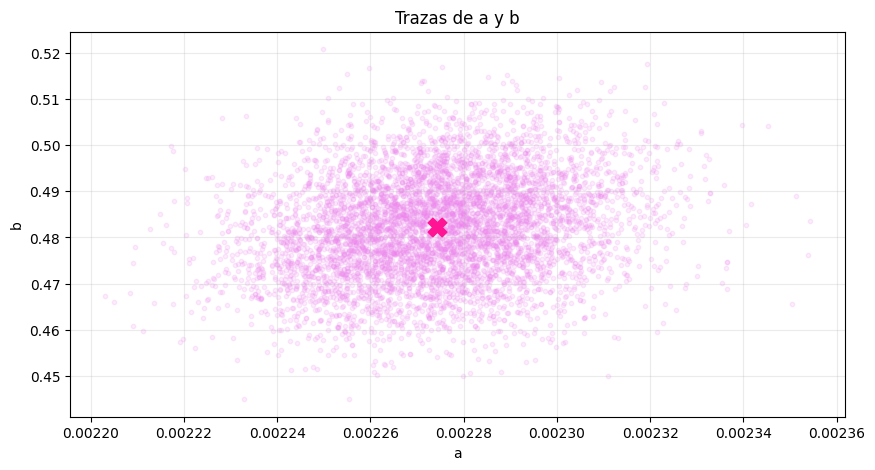

In [23]:
a_muestras = idata.posterior["a"].values.flatten()
b_muestras = idata.posterior["b"].values.flatten()

a_estimado = np.mean(a_muestras)
b_estimado = np.mean(b_muestras)

plt.figure(figsize=(10, 5))

plt.scatter(
    a_muestras,
    b_muestras,
    alpha=0.15,
    s=10,
    color="violet"
)

plt.scatter(
    a_estimado, b_estimado,
    color="deeppink",
    marker="X",
    s=180,
    label="Punto Estimado"
)

plt.title("Trazas de a y b")
plt.xlabel("a")
plt.ylabel("b")
plt.grid(alpha=0.25)
plt.show()

In [24]:
print(f"Estimación de a: {a_estimado:.6f}")
print(f"Estimación de b: {b_estimado:.6f}")

Estimación de a: 0.002274
Estimación de b: 0.482189


##<font color= "lightpink"> **Conclusiones**

El ajuste bayesiano del modelo SIR permite estimar los parámetros de transmisión y recuperación a partir de los datos observados de una epidemia. Mediante PyMC se definieron distribuciones previas, una verosimilitud Poisson y un procedimiento de muestreo MCMC para aproximar las distribuciones posteriores.

Las gráficas posteriores permiten analizar los valores plausibles de los parámetros y su incertidumbre. Las trazas y los indicadores de convergencia permiten evaluar la calidad del muestreo. Finalmente, la comparación entre los datos observados y la trayectoria simulada permite valorar la capacidad del modelo para reproducir la evolución de los infectados.

Los resultados numéricos deben reportarse con base en la ejecución del código, incluyendo las estimaciones de \(a\) y \(b\), sus intervalos creíbles del 95 % y los indicadores de convergencia.

Entre las limitaciones se encuentran el supuesto de población cerrada, la constancia de los parámetros epidemiológicos y el uso de una distribución Poisson para los conteos. Estas hipótesis pueden afectar la correspondencia entre la simulación y los datos reales.